In [1]:
from models.unet import SiameseUNet
from lightning import Trainer
from lightning.pytorch.loggers import TensorBoardLogger
from data.data import SpagDataModule
from lightning.pytorch.callbacks import ModelCheckpoint

data_module=SpagDataModule(
    root_folder="/home/tristan/data/CTC_SINETRA_seg/Fluo-N2DH-GOWT1",
    subfolders=["01","02","02"],
    batch_size=1,
    max_length_of_training_samples=2,
    max_length_of_validation_samples=2,
    max_length_of_testing_samples=100,
    expected_min=0,
    expected_max=255
)




Found min and max values of images:  0 224
Normalizing images to [0, 1] using expected_min and expected_max:  0 255
Found min and max values of images:  0 155
Normalizing images to [0, 1] using expected_min and expected_max:  0 255
Found min and max values of images:  0 182
Normalizing images to [0, 1] using expected_min and expected_max:  0 255
######## Successfully loaded datasets ########
Root folder: /home/tristan/data/CTC_SINETRA_seg/Fluo-N2DH-GOWT1
Train dataset length: 2
Val dataset length: 2
Test dataset length: 92
###############################################


In [2]:
# import torch

# # 1. Instantiate the model with the exact same arguments used during training
# model = SiameseUNet(
#     # in_channels=3,  (Add your initialization arguments here if you have any)
#     # feature_dim=64
# )

# checkpoint_path = "/mnt/helix/FeatureNet_seg/training_logs/SiameseUNet/32feat_True_pos/DIC-C2DH-HeLa/version_0/checkpoints/unet_epoch_100.ckpt"

# # 2. Load the raw checkpoint file
# checkpoint = torch.load(checkpoint_path, map_location="cpu")

# # 3. Handle different save formats
# if "state_dict" in checkpoint:
#     # Sometimes raw saves still wrap the weights in a 'state_dict' key
#     model.load_state_dict(checkpoint["state_dict"])
# else:
#     # Otherwise, the checkpoint is likely just the weights dictionary itself
#     model.load_state_dict(checkpoint)

# model.eval()

In [3]:
model= SiameseUNet.load_from_checkpoint(
    # checkpoint_path="/mnt/helix/FeatureNet_seg/training_logs/SiameseUNet/32feat_True_pos/DIC-C2DH-HeLa/version_0/checkpoints/best_model_epoch=34.ckpt")
    checkpoint_path='./training_logs/SiameseUNet_aug/Fluo-N2DH-GOWT1/version_0/checkpoints/best_model.ckpt')
model.eval()

SiameseUNet(
  (loss_fn_seg): BCEWithLogitsLoss()
  (model): SiameseUNetBase(
    (down): UnetDown(
      (encoder): ModuleList(
        (0): UNetBlock(
          (block): Sequential(
            (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (1): ReLU(inplace=True)
            (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (3): ReLU(inplace=True)
          )
        )
        (1): UNetBlock(
          (block): Sequential(
            (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (1): ReLU(inplace=True)
            (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (3): ReLU(inplace=True)
          )
        )
        (2): UNetBlock(
          (block): Sequential(
            (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (1): ReLU(inplace=True)
            (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1

In [ ]:
preds=model.predict_from_dataloader(data_module.test_dataloader(), thresh=0.5, disable_tqdm=False, keep_pseudo_probs=True)

Predicting: 100%|██████████| 20/20 [00:04<00:00,  4.35it/s]


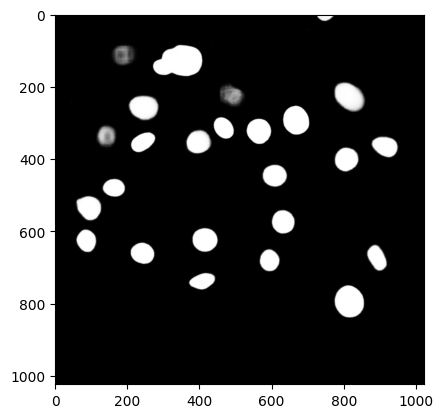

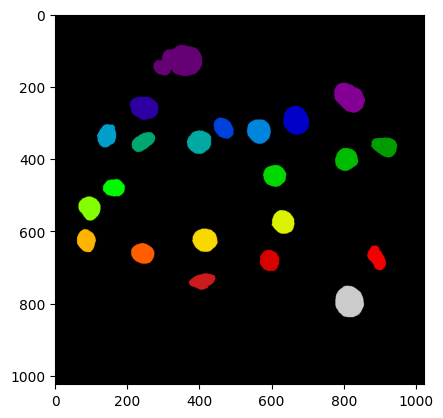

In [ ]:
import matplotlib.pyplot as plt
from torch import sigmoid
plt.figure()
plt.imshow(preds[0][0].detach().cpu().numpy().squeeze(), cmap='gray')

gt=data_module.test_ds[0][1].detach().cpu().numpy().squeeze()

plt.figure()
plt.imshow(gt, cmap='nipy_spectral')

Running t-SNE on 5000 pixels...


/tmp/ipykernel_62884/850742483.py:57: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(unique_labels))


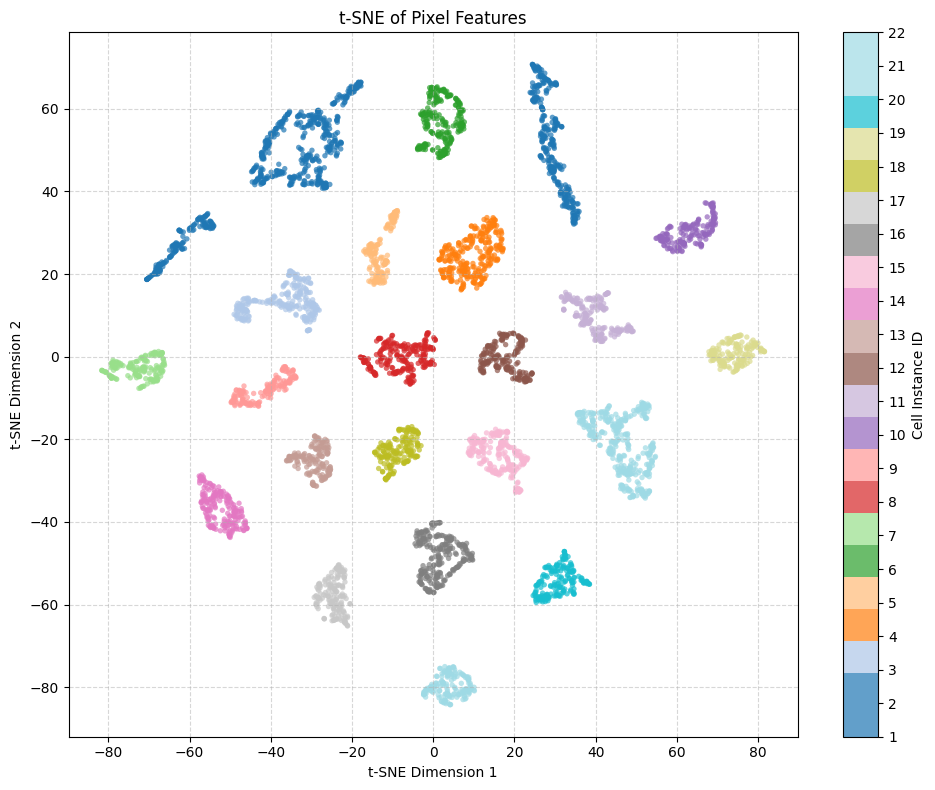

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

def visualize_features_tsne(features, instance_mask, max_samples=5000, include_background=False):
    """
    Applies t-SNE to a feature map to visualize if pixels from the same 
    cell cluster together.
    
    Args:foreground
        features: Tensor of shape (C, H, W)
        instance_mask: Tensor of shape (H, W) with ground truth integer labels
        max_samples: Maximum number of pixels to process (t-SNE is slow for N > 10000)
        include_background: Whether to include background pixels (ID=0) in the plot
    """

    C, H, W = features.shape
    
    # 2. Flatten spatial dimensions
    # features_flat: (H*W, C)
    # mask_flat: (H*W,)
    features_flat = features.reshape(C, -1).T
    mask_flat = instance_mask.flatten()
    
    # 3. Filter pixels (remove background if requested)
    if include_background:
        valid_indices = np.arange(len(mask_flat))
    else:
        valid_indices = np.where(mask_flat > 0)[0]
        
    if len(valid_indices) == 0:
        print("No foreground pixels found to plot.")
        return
        
    # 4. Randomly subsample to keep t-SNE fast
    if len(valid_indices) > max_samples:
        selected_indices = np.random.choice(valid_indices, size=max_samples, replace=False)
    else:
        selected_indices = valid_indices
        
    sampled_features = features_flat[selected_indices]
    sampled_labels = mask_flat[selected_indices]
    
    # 5. Run t-SNE
    print(f"Running t-SNE on {len(sampled_features)} pixels...")
    # init='pca' is generally more stable than random initialization
    tsne = TSNE(n_components=2, init='pca', learning_rate='auto', random_state=42)
    embeddings = tsne.fit_transform(sampled_features)
    
    # 6. Plotting
    plt.figure(figsize=(10, 8))
    
    # Use a distinct colormap for instances
    unique_labels = np.unique(sampled_labels)
    # 'tab20' provides 20 distinct colors, which loops if you have >20 cells
    cmap = plt.cm.get_cmap('tab20', len(unique_labels)) 
    
    # Scatter plot
    scatter = plt.scatter(
        embeddings[:, 0], 
        embeddings[:, 1], 
        c=sampled_labels, 
        cmap=cmap, 
        alpha=0.7, 
        s=15, # marker size
        edgecolors='none'
    )
    
    # Add a colorbar and labels
    cbar = plt.colorbar(scatter, ticks=unique_labels)
    cbar.set_label('Cell Instance ID')
    
    plt.title("t-SNE of Pixel Features")
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


features=preds[0][1].detach().cpu().numpy().squeeze()
instance_mask=gt

visualize_features_tsne(features, instance_mask, max_samples=5000, include_background=False)


In [ ]:
import torch
import numpy as np
from sklearn.cluster import DBSCAN, MeanShift

def cluster_features_to_instances(dense_features, foreground_mask, method='dbscan', margin=1.5, add_postitional_encoding=False):
    """
    Clusters 64-d pixel embeddings into discrete instance masks.
    
    Args:
        dense_features: Tensor or numpy array of shape (C, H, W)
        foreground_mask: Binary mask of shape (H, W) where 1=cell, 0=background.
                         (Usually predicted by a parallelfirst_try/SiameseUNet/version_1/checkpoints/last.ckpt semantic branch).
        method: 'dbscan' (recommended) or 'meanshift'.
        margin: The distance margin used during your contrastive training.
        
    Returns:
        instance_mask: Numpy array of shape (H, W) with unique integer IDs for cells.
    """
    # 1. Convert to numpy
    if isinstance(dense_features, torch.Tensor):
        dense_features = dense_features.detach().cpu().squeeze().numpy()
    if isinstance(foreground_mask, torch.Tensor):
        foreground_mask = foreground_mask.detach().cpu().squeeze().numpy()
    
    if add_postitional_encoding:
        # Add normalized positional encoding to the features
        H, W = foreground_mask.shape
        y_coords, x_coords = np.meshgrid(np.arange(H), np.arange(W), indexing='ij')
        y_coords = y_coords / H  # Normalize to [0, 1]
        x_coords = x_coords / W  # Normalize to [0, 1]
        
        # Stack positional encodings with dense features
        dense_features = np.concatenate([dense_features, y_coords[None, :, :], x_coords[None, :, :]], axis=0)

    C, H, W = dense_features.shape
    
    # 2. Flatten features: (H*W, C)
    features_flat = dense_features.reshape(C, -1).T
    fg_mask_flat = foreground_mask.flatten() > 0
    
    # 3. Extract only foreground pixels to cluster
    # This drastically speeds up clustering and prevents background noise
    fg_features = features_flat[fg_mask_flat]
    
    # Create an empty instance mask (0 = background)
    instance_mask_flat = np.zeros(H * W, dtype=np.int32)
    
    # Edge case: No foreground detected
    if len(fg_features) == 0:
        return instance_mask_flat.reshape(H, W)
        
    # 4. Configure the Clustering Algorithm
    if method == 'dbscan':
        # eps should be slightly less than your training margin. 
        # If your margin was 1.5, points within the same cluster should be 
        # very close (e.g., < 0.5), while different clusters are > 1.5 apart.
        eps_threshold = margin * 0.2
        
        # min_samples prevents tiny noise dots from becoming cells.
        # Set this based on your minimum expected cell size (in pixels).
        clusterer = DBSCAN(eps=eps_threshold, min_samples=2000, metric='euclidean')
        
    elif method == 'meanshift':
        # MeanShift bandwidth is also tied to your margin
        clusterer = MeanShift(bandwidth=margin * 0.5, bin_seeding=True)
    
    elif method == 'hdbscan':
        from hdbscan import HDBSCAN
        # HDBSCAN is a density-based clustering algorithm that can handle variable density clusters.
        # The min_cluster_size parameter controls the smallest size of clusters to consider.
        clusterer = HDBSCAN(min_cluster_size=1000, metric='euclidean')
        

        
    else:
        raise ValueError("Method must be 'dbscan' or 'meanshift'")

    # 5. Run Clustering
    print(f"Clustering {len(fg_features)} foreground pixels using {method.upper()}...")
    labels = clusterer.fit_predict(fg_features)
    
    # DBSCAN returns -1 for noise/outliers. We want to shift our IDs so they 
    # start at 1, keeping 0 exclusively for the background.
    if method == 'dbscan':
        # Map noise (-1) to background (0), and shift other clusters up by 1
        labels = np.where(labels == -1, -1, labels) + 1
    else:
        # MeanShift returns labels 0, 1, 2... Shift up by 1.
        labels = labels + 1

    # 6. Reconstruct the 2D Instance Mask
    # Place the cluster labels back into the original spatial locations
    instance_mask_flat[fg_mask_flat] = labels
    instance_mask_2d = instance_mask_flat.reshape(H, W)
    print(f"Detected {len(np.unique(instance_mask_2d)) - 1} instances.")
    return instance_mask_2d


# foreground_mask = (sigmoid(preds[0][0]).detach().cpu().numpy().squeeze() > 0.5).astype(np.uint8)
# instance_mask = cluster_features_to_instances(preds[0][1], foreground_mask, method='dbscan', margin=1.5)
# unique_labels=np.unique(instance_mask)
# cmap = plt.cm.get_cmap('tab20', len(unique_labels)) 
   
# plt.figure(figsize=(10,10))
# plt.imshow(instance_mask, cmap=cmap)
# plt.colorbar()
# print(f"Number of detected instances: {len(np.unique(instance_mask)) - 1}")  # Subtract 1 for background
# print("GT number of instances:", len(np.unique(gt)) - 1)

In [ ]:
model=None

instance_masks=[]
for i in range(0, len(preds)):
    foreground_mask = (preds[i][0].detach().cpu().numpy().squeeze() > 0.5).astype(np.uint8)
    print(foreground_mask.min(), foreground_mask.max())
    instance_mask = cluster_features_to_instances(preds[i][1], foreground_mask, method='hdbscan', margin=1.5)
    instance_masks.append(instance_mask)
    

0 1
Clustering 77602 foreground pixels using HDBSCAN...
Detected 23 instances.
0 1
Clustering 76789 foreground pixels using HDBSCAN...
Detected 22 instances.
0 1
Clustering 78604 foreground pixels using HDBSCAN...
Detected 23 instances.
0 1
Clustering 78197 foreground pixels using HDBSCAN...
Detected 23 instances.
0 1
Clustering 81784 foreground pixels using HDBSCAN...
Detected 24 instances.
0 1
Clustering 82079 foreground pixels using HDBSCAN...
Detected 24 instances.
0 1
Clustering 82055 foreground pixels using HDBSCAN...
Detected 24 instances.
0 1
Clustering 81828 foreground pixels using HDBSCAN...
Detected 24 instances.
0 1
Clustering 80583 foreground pixels using HDBSCAN...
Detected 23 instances.
0 1
Clustering 81234 foreground pixels using HDBSCAN...
Detected 23 instances.
0 1
Clustering 82317 foreground pixels using HDBSCAN...
Detected 23 instances.
0 1
Clustering 82254 foreground pixels using HDBSCAN...
Detected 23 instances.
0 1
Clustering 81345 foreground pixels using HDBSCAN

In [ ]:
import napari
import tifffile
gt=[data_module.test_ds[i][1].detach().cpu().numpy().squeeze() for i in range(len(data_module.test_ds))]
viewer=napari.Viewer()
viewer.add_image(tifffile.imread("/home/tristan/data/CTC_SINETRA_seg/Fluo-N2DH-GOWT1/02/video.tiff"), name="raw")
viewer.add_labels(np.array(gt).astype(np.uint8), name="GT")
viewer.add_labels(np.array(instance_masks).astype(np.uint8), name="Predicted Instances")

<Labels layer 'Predicted Instances' at 0x74b1a47ead40>

In [ ]:
#test augmentations 
from augmentations import train_transform
import os
from data.data import SpagDataModule
dir_name="Fluo-N2DH-GOWT1"
augmenter=train_transform

root_folder=os.path.join("/home/tristan/data/CTC_SINETRA_seg/", dir_name)
subfolders=["01","02","02"]

data_module=SpagDataModule(
    root_folder=root_folder,
    subfolders=subfolders,
    batch_size=1,
    max_length_of_training_samples=200,
    max_length_of_validation_samples=2,
    max_length_of_testing_samples=2,
    expected_min=0,
    expected_max=255,
    augmenter= augmenter
)


Found min and max values of images:  0 255
Normalizing images to [0, 1] using expected_min and expected_max:  0 255
Found min and max values of images:  0 155
Normalizing images to [0, 1] using expected_min and expected_max:  0 255
Found min and max values of images:  0 155
Normalizing images to [0, 1] using expected_min and expected_max:  0 255
######## Successfully loaded datasets ########
Root folder: /home/tristan/data/CTC_SINETRA_seg/Fluo-N2DH-GOWT1
Train dataset length: 92
Val dataset length: 2
Test dataset length: 2
###############################################


In [ ]:
images=[]
masks=[]
for i in range(0, len(data_module.train_ds)):
    
    data=data_module.train_ds.__getitem__(i)
    images.append(data[0].detach().cpu().numpy().squeeze())
    masks.append(data[1].detach().cpu().numpy().squeeze())
    print(images[-1].min(), images[-1].max(), masks[-1].min(), masks[-1].max())
import napari
viewer=napari.Viewer()
import numpy as np
viewer.add_image(np.array(images), name="raw")
viewer.add_labels(np.array(masks).astype(np.uint8), name="GT")


0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 22.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 24.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 23.0
0.0 1.0 0.0 22.0
0.0 1.0 0.0 21.0
0.0 1.0 0.0 21.0
0.0 1.0 0.0 21.0
0.0 1.0 0.0 21.0
0.0 1.0 0.0 21.0
0.0 1.0 0.0 21.0
0.0 1.0 0.0 21

<Labels layer 'GT' at 0x74b1924ded10>